# Household Electricity Consumption Prediction

## Exploratory Data Analysis (EDA)

This notebook explores the household electricity consumption dataset
and identifies important patterns and relationships before machine learning.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv(r"C:\Users\Shehan\OneDrive\Desktop\PROJECT_\data\household_power_consumption.csv")
df.head()

,Month,Province,District,Household_Type,Household_Size,House_Area_m2,Bedrooms,AC_Units,Fans,Refrigerators,...,Other_High_Power_Appliances,Avg_Daily_AC_Hours,Avg_Daily_Fan_Hours,Avg_Daily_TV_Hours,Avg_Daily_Cooking_Hours,Solar_PV,Solar_Capacity_kW,Avg_Temperature_C,Previous_Month_kWh,Target_Monthly_kWh
0,January,Eastern,Ampara,Single_Family,4,69.1,1,1.0,4,1,...,3,5.1,4.7,3.5,3.3,No,0.0,30.3,369.7,350.8
1,January,Eastern,Ampara,Apartment,6,54.1,2,0.0,7,1,...,0,0.0,NaN,6.3,3.0,No,0.0,30.3,290.9,281.8
2,January,North Central,Anuradhapura,Single_Family,2,196.9,5,0.0,3,1,...,1,0.0,10.7,4.1,3.9,No,NaN,25.4,241.6,277.9
3,January,North Central,Anuradhapura,Single_Family,4,122.8,3,0.0,4,2,...,3,0.0,9.2,5.7,3.7,No,0.0,27.4,270.7,286.7
4,January,Uva,Badulla,Single_Family,5,93.9,2,0.0,5,1,...,2,0.0,4.7,2.7,1.4,No,0.0,29.6,307.3,303.0


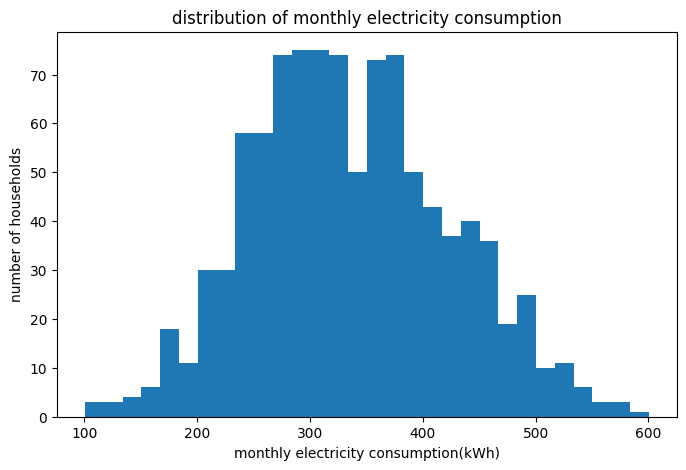

In [3]:
plt.figure(figsize=(8,5))
plt.hist(df["Target_Monthly_kWh"],bins=30)
plt.xlabel("monthly electricity consumption(kWh)")
plt.ylabel("number of households")
plt.title("distribution of monthly electricity consumption")
plt.show()

In [4]:
df["Target_Monthly_kWh"].describe()

count    1000.000000
mean      336.968300
std        87.105358
min       100.700000
25%       274.250000
50%       330.050000
75%       393.275000
max       600.200000
Name: Target_Monthly_kWh, dtype: float64

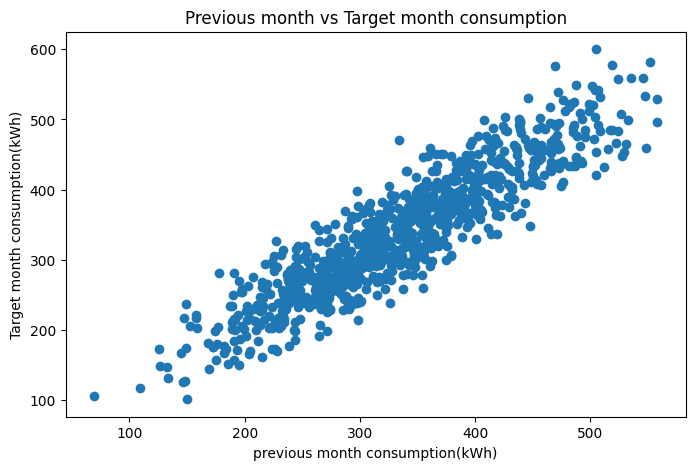

In [5]:
plt.figure(figsize=(8,5))
plt.scatter(df["Previous_Month_kWh"],df["Target_Monthly_kWh"])
plt.xlabel("previous month consumption(kWh)")
plt.ylabel("Target month consumption(kWh)")
plt.title("Previous month vs Target month consumption")
plt.show()

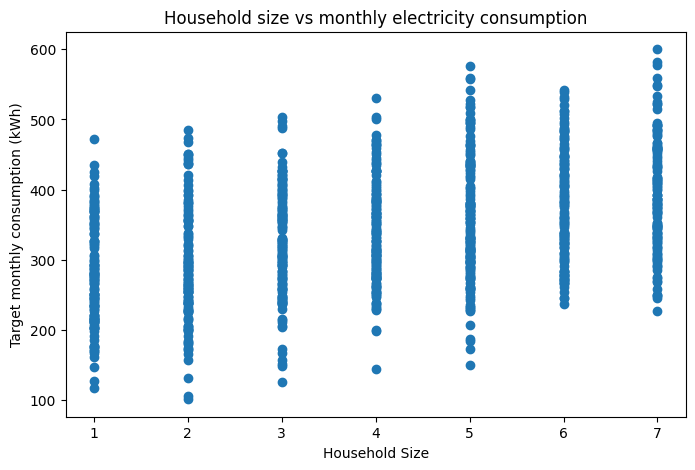

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Household_Size"],
    df["Target_Monthly_kWh"]
)

plt.xlabel("Household Size")
plt.ylabel("Target monthly consumption (kWh)")
plt.title("Household size vs monthly electricity consumption")

plt.show()

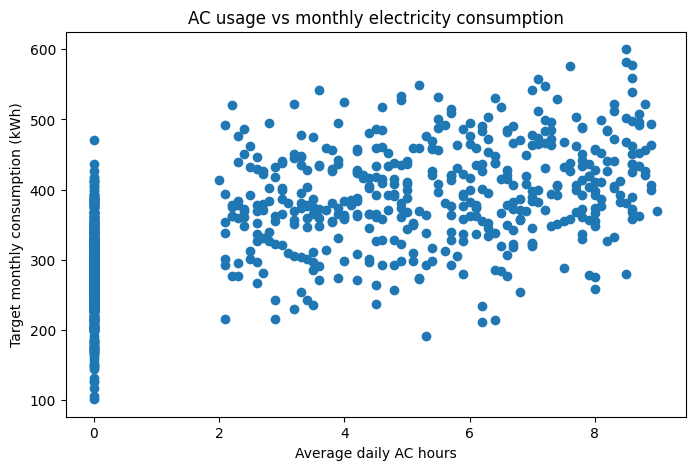

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Avg_Daily_AC_Hours"],
    df["Target_Monthly_kWh"]
)

plt.xlabel("Average daily AC hours")
plt.ylabel("Target monthly consumption (kWh)")
plt.title("AC usage vs monthly electricity consumption")

plt.show()

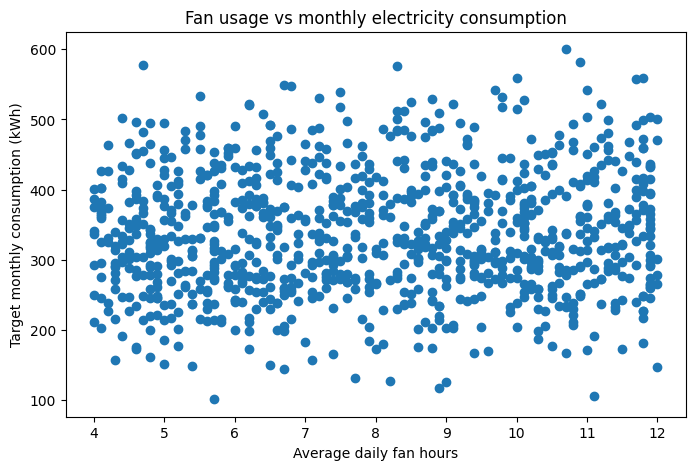

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Avg_Daily_Fan_Hours"],
    df["Target_Monthly_kWh"]
)

plt.xlabel("Average daily fan hours")
plt.ylabel("Target monthly consumption (kWh)")
plt.title("Fan usage vs monthly electricity consumption")

plt.show()

In [9]:
df["Solar_PV"].value_counts()

Solar_PV
No     745
Yes    255
Name: count, dtype: int64

Text(0.5, 1.0, 'Solar PV vs monthly electricity consumption')

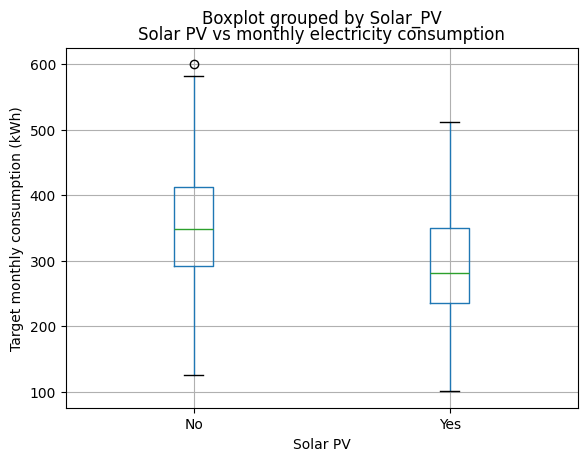

In [10]:
df.boxplot(column="Target_Monthly_kWh",by="Solar_PV")
plt.xlabel("Solar PV")
plt.ylabel("Target monthly consumption (kWh)")
plt.title("Solar PV vs monthly electricity consumption")

In [11]:
df.groupby("Province")["Target_Monthly_kWh"].mean()

Province
Central          347.680645
Eastern          346.770690
North Central    336.379630
North Western    328.617593
Northern         349.877670
Sabaragamuwa     326.072549
Southern         329.209836
Uva              334.182143
Western          336.030147
Name: Target_Monthly_kWh, dtype: float64

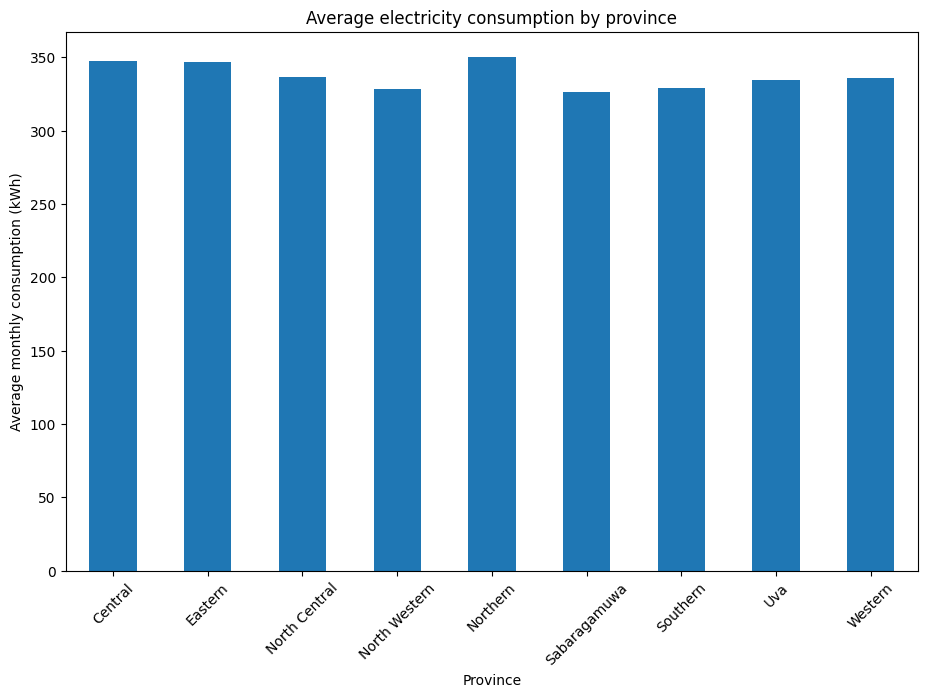

In [12]:
province_mean=df.groupby("Province")["Target_Monthly_kWh"].mean()
province_mean.plot(kind="bar",figsize=(11,7))
plt.xlabel("Province")
plt.ylabel("Average monthly consumption (kWh)")
plt.title("Average electricity consumption by province")

plt.xticks(rotation=45)

plt.show()



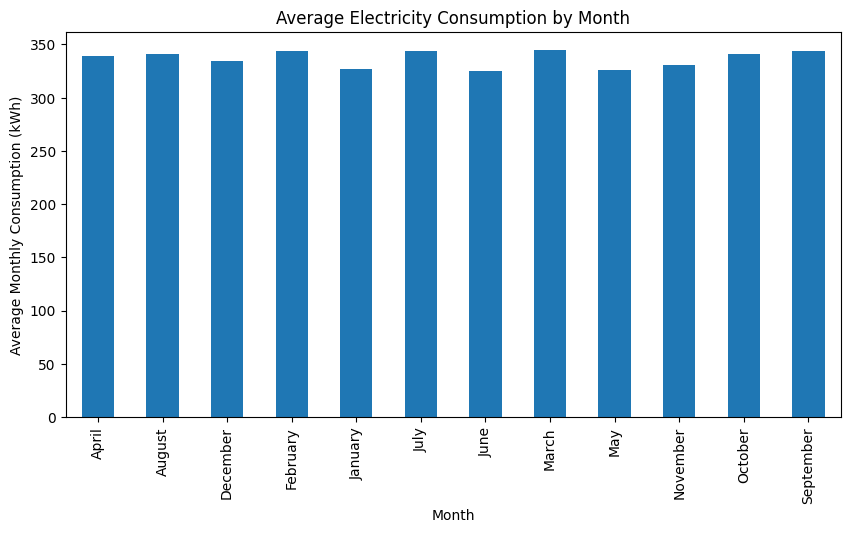

Month
April        338.764835
August       340.926136
December     334.501235
February     343.712644
January      326.642667
July         344.157353
June         325.153012
March        344.496154
May          326.389552
November     330.887640
October      340.871765
September    343.436111
Name: Target_Monthly_kWh, dtype: float64

In [13]:
month_mean = df.groupby("Month")["Target_Monthly_kWh"].mean()

month_mean.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Month")
plt.ylabel("Average Monthly Consumption (kWh)")
plt.title("Average Electricity Consumption by Month")

plt.show()
month_mean

In [14]:
numeric_df=df.select_dtypes(include="number")
correlation=numeric_df.corr()
correlation["Target_Monthly_kWh"].sort_values(ascending=False)

Target_Monthly_kWh             1.000000
Previous_Month_kWh             0.909313
AC_Units                       0.657125
Avg_Daily_AC_Hours             0.648112
Fans                           0.435010
Household_Size                 0.431150
TVs                            0.175239
Water_Heaters                  0.147344
House_Area_m2                  0.132847
Bedrooms                       0.123540
Computers                      0.110839
Washing_Machines               0.107650
Avg_Temperature_C              0.100802
Other_High_Power_Appliances    0.093953
Refrigerators                  0.058060
Avg_Daily_Fan_Hours            0.057614
Avg_Daily_TV_Hours             0.048768
Avg_Daily_Cooking_Hours        0.010914
Solar_Capacity_kW             -0.343183
Name: Target_Monthly_kWh, dtype: float64

In [15]:
!pip install seaborn


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import seaborn as sns

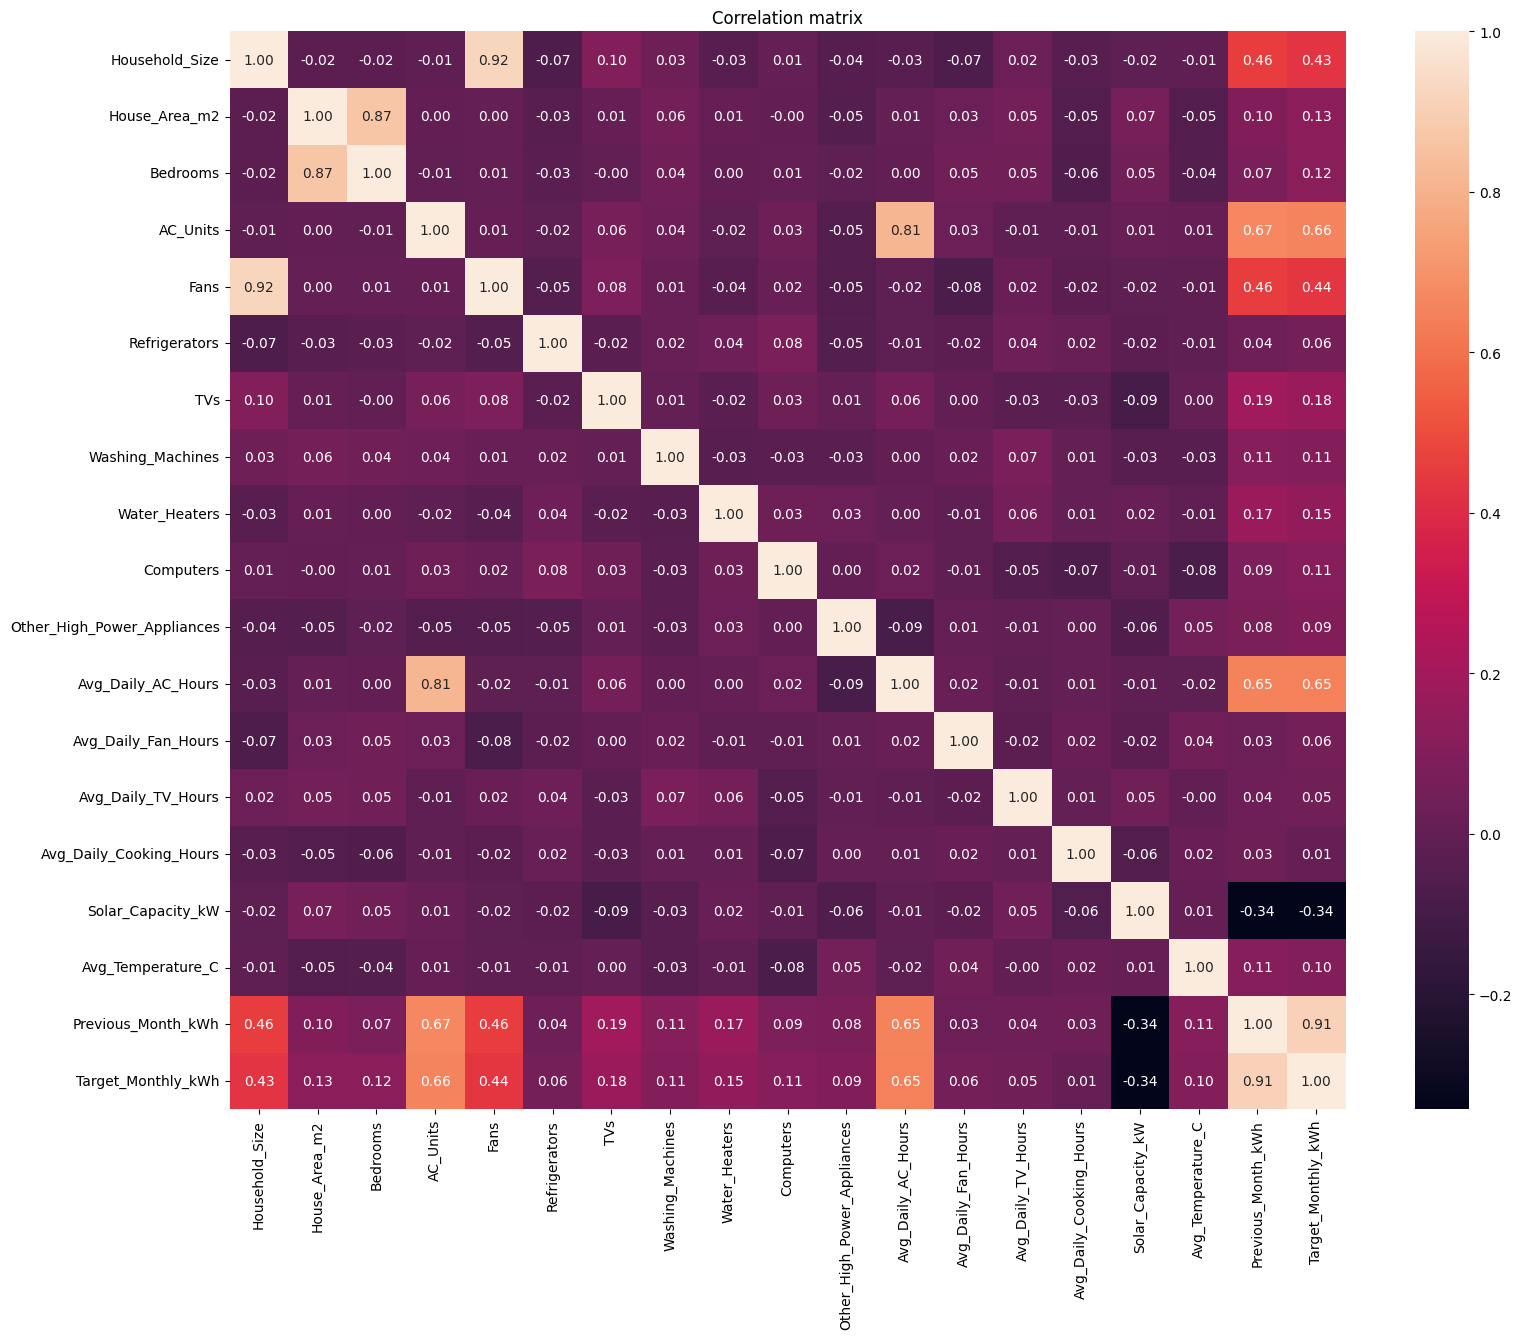

In [17]:
plt.figure(figsize=(18,14))

sns.heatmap(numeric_df.corr(),annot=True,fmt=".2f")
plt.title("Correlation matrix")
plt.show()